# Blackbody spectra and the peak-wavelength locus

Planck spectra are evaluated at several temperatures, with the wavelength of each maximum marked.

$$E_\lambda=\frac{2\pi hc^2}{\lambda^5[\exp(hc/(\lambda kT))-1]}.$$

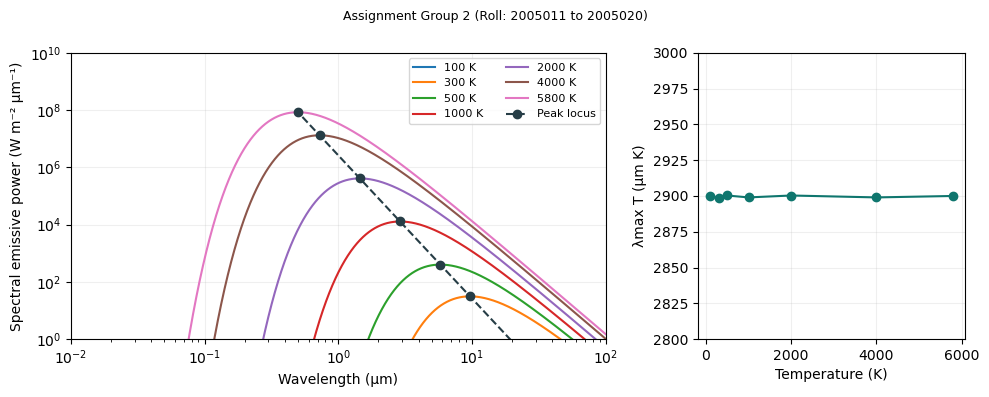

λmax T (µm K): [2899.65 2898.81 2900.32 2898.99 2900.32 2898.99 2900.  ]


In [1]:
import numpy as np
import matplotlib.pyplot as plt

h, c, k = 6.626e-34, 2.9979e8, 1.38e-23
wavelength = np.logspace(-2, 2, 10000)  # µm
temperatures = np.array([100, 300, 500, 1000, 2000, 4000, 5800])

def emission(wavelength_um, temperature):
    wavelength_m = wavelength_um * 1e-6
    exponent = h*c/(wavelength_m*k*temperature)
    with np.errstate(over='ignore'):
        return 2*np.pi*h*c*c/(wavelength_m**5*np.expm1(exponent))*1e-6

fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios':[2, 1]})
fig.suptitle('Assignment Group 2 (Roll: 2005011 to 2005020)', fontsize=9)
peaks = []
for temperature in temperatures:
    power = emission(wavelength, temperature)
    peak = np.argmax(power)
    peaks.append([wavelength[peak], power[peak]])
    axes[0].loglog(wavelength, power, label=f'{temperature} K')
peaks = np.array(peaks)
axes[0].loglog(peaks[:,0], peaks[:,1], 'o--', color='#263d46', label='Peak locus')
axes[0].set(xlim=(.01, 100), ylim=(1, 1e10), xlabel='Wavelength (µm)', ylabel='Spectral emissive power (W m⁻² µm⁻¹)')
axes[0].legend(fontsize=8, ncol=2)
products = peaks[:,0]*temperatures
axes[1].plot(temperatures, products, 'o-', color='#0f766e')
axes[1].set(xlabel='Temperature (K)', ylabel='λmax T (µm K)', ylim=(2800, 3000))
for ax in axes:
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
assert np.max(np.abs(products-2898)) < 5
print('λmax T (µm K):', np.round(products, 2))